In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import os

In [2]:
folders = ['results_blg_-1_to_1V_hbn15', 'results_blg_-0.3_to_0.3V_hbn15']

In [3]:
results_folder = Path.cwd() / folders[1]

back_gates = np.load(results_folder / 'back_gates.npy')
charges = np.load(results_folder / 'charges.npy')
potentials = np.load(results_folder / 'potentials.npy')
succs = np.load(results_folder / 'successes.npy')
top_cocs = np.load(results_folder / 'top_cocs.npy')
bot_cocs = np.load(results_folder / 'bot_cocs.npy')
sep_idxs = np.load(results_folder / 'sep_indxs.npy')
seps = np.load(results_folder / 'separations.npy')
y_cuts = np.load(results_folder / 'y_cuts.npy')
other_params = np.load(results_folder / 'box_width-cut_percentage-larger_cut_percentage.npy')

In [4]:
vac_box_width = other_params[0]
cut_percentage = other_params[1]
larger_cut_percentage = other_params[2]
hbn_height = other_params[3]
charge_record_rate = other_params[4]

Text(0, 0.5, '$d \\: [\\AA]$')

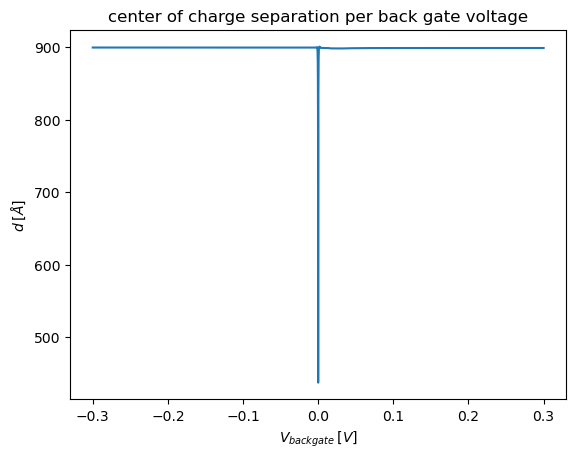

In [5]:
plt.plot(back_gates, seps, '-')
plt.title('center of charge separation per back gate voltage')
plt.xlabel('$V_{{backgate}} \\: [V]$')
plt.ylabel('$d \\: [\\AA]$')

Text(0, 0.5, '$d \\: [\\AA]$')

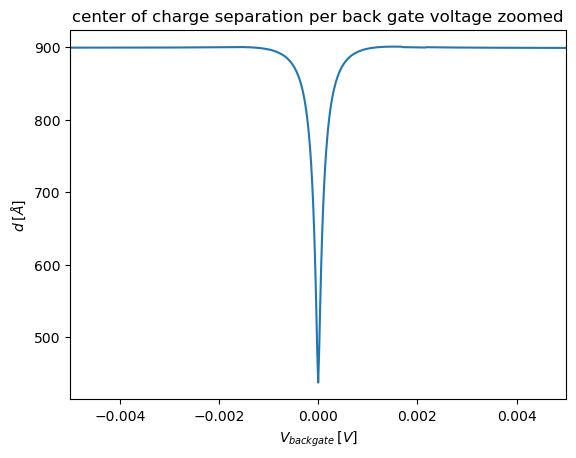

In [6]:
plt.plot(back_gates, seps, '-')
plt.xlim((-0.005, 0.005))
plt.title('center of charge separation per back gate voltage zoomed')
plt.xlabel('$V_{{backgate}} \\: [V]$')
plt.ylabel('$d \\: [\\AA]$')

In [7]:
fem_n = charges.shape[1]
cut_index = int(cut_percentage/2 * fem_n)

dx = vac_box_width/(fem_n - 1)
x_max = (fem_n - 1) * dx
x = np.linspace(0, x_max, fem_n)
y = np.linspace(0, x_max, fem_n)

x = x[cut_index:fem_n - cut_index]
y = y[cut_index:fem_n - cut_index]

In [8]:
print(top_cocs.shape)
print(back_gates.shape)
print(charge_record_rate)

(150, 2)
(1500,)
10.0


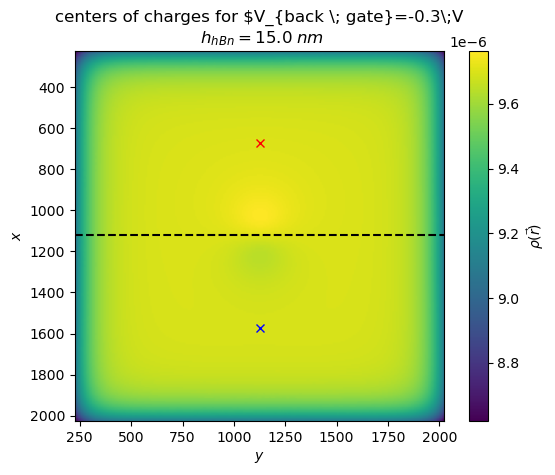

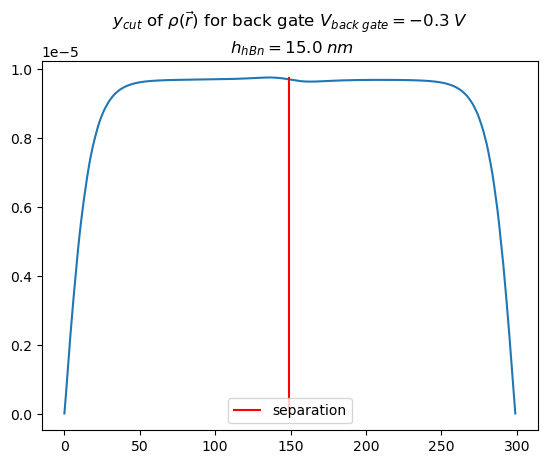

In [10]:
plot_idx = 0

voltage = np.round(back_gates[int(plot_idx * charge_record_rate)], 6)
charges_cut = charges[:, cut_index:fem_n - cut_index, cut_index:fem_n - cut_index]

plt.imshow(charges_cut[plot_idx, :, :], extent=[x.min(), x.max(), y.max(), y.min()])
plt.plot(top_cocs[plot_idx, 1], top_cocs[plot_idx, 0], 'rx')
plt.plot(bot_cocs[plot_idx, 1], bot_cocs[plot_idx, 0], 'bx')

plt.hlines(x[sep_idxs[plot_idx]], x.min(), x.max(), color='black', linestyle='dashed')
plt.colorbar(label='$\\rho(\\vec{{r}})$')
plt.title(f'centers of charges for $V_{{back \\; gate}}={voltage}\\;V\n $h_{{hBn}}={hbn_height/10}\\;nm$')
plt.xlabel('$y$')
plt.ylabel('$x$')

plt.show()

#y_test = test_solver.cut_through_charge#[larger_cut_index:test_solver.fem_n - larger_cut_index]
plt.plot(y_cuts[plot_idx, :])
plt.vlines(sep_idxs[plot_idx] + cut_index, np.min(y_cuts[plot_idx, :]), np.max(y_cuts[plot_idx, :]), color='r', label='separation')
plt.title(f'$y_{{cut}}$ of $\\rho(\\vec{{r}})$ for back gate $V_{{back\\;gate}}={voltage} \\; V$\n $h_{{hBn}}={hbn_height/10}\\;nm$')
plt.legend()

plt.show()

In [ ]:
print(back_gates[int((plot_idx)* charge_record_rate)])

-0.3294117647058824


In [ ]:
# if this equals the number of back gates, all scipy.optimize.root where succesful
print('number of back gates: ', back_gates.shape[0])
print('sum over all successes: ',np.sum(succs))

number of back gates:  1800
sum over all successes:  1800


Text(0, 0.5, '$x$')

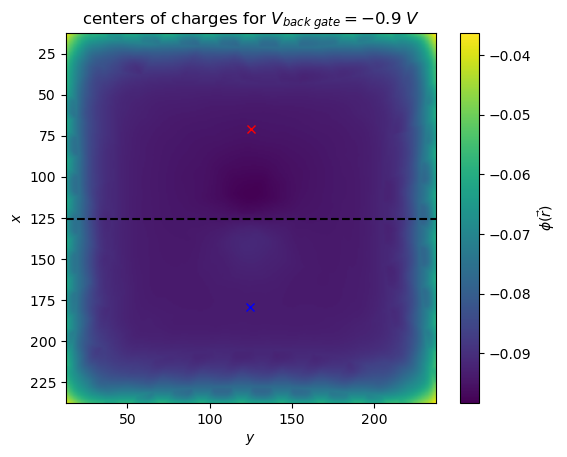

In [ ]:
plot_idx = 50

voltage = np.round(back_gates[plot_idx * 10], 6)
potentials_cut = potentials[:, cut_index:fem_n - cut_index, cut_index:fem_n - cut_index]

plt.imshow(potentials_cut[plot_idx, :, :], extent=[x.min(), x.max(), y.max(), y.min()])
plt.plot(top_cocs[plot_idx, 1], top_cocs[plot_idx, 0], 'rx')
plt.plot(bot_cocs[plot_idx, 1], bot_cocs[plot_idx, 0], 'bx')

plt.hlines(x[sep_idxs[plot_idx]], x.min(), x.max(), color='black', linestyle='dashed')
plt.colorbar(label='$\\phi(\\vec{{r}})$')
plt.title(f'centers of charges for $V_{{back\\;gate}}={voltage}\\;V$')
plt.xlabel('$y$')
plt.ylabel('$x$')

In [ ]:
plt.plot(back_gates, dipole_moments/(solver.vac_box_width * solver.vac_box_width), 'x')
plt.xlabel('$V_{{backgate}} \\: [V]$')
plt.ylabel('$\\frac{|\\vec{{p}}|}{A} \\: [\\frac{e}{\\AA}]$')
plt.title('induced dipole moment per area')

NameError: name 'dipole_moments' is not defined

In [ ]:
plt.plot(back_gates, Q_tops, 'x', label='$Q_{top}$')
plt.plot(back_gates, Q_bots, 'x', label='$Q_{bot}$')
plt.title('charges')
plt.legend()
plt.xlabel('$V_{{backgate}} \\: [V]$')
plt.ylabel('$Q[e]$')